___
<a href='https://cafe.naver.com/jmhonglab'><p style="text-align:center;"><img src='https://lh3.googleusercontent.com/lY3ySXooSmwsq5r-mRi7uiypbo0Vez6pmNoQxMFhl9fmZJkRHu5lO2vo7se_0YOzgmDyJif9fi4_z0o3ZFdwd8NVSWG6Ea80uWaf3pOHpR4GHGDV7kaFeuHR3yAjIJjDgfXMxsvw=w2400'  class="center" width="50%" height="50%"/></p></a>
___
<center><em>Content Copyright by HongLab, Inc.</em></center>

# 컴퓨터 비전 맛보기

인간에게 시각(vision)은 매우 중요한 감각입니다. [컴퓨터 비전](https://en.wikipedia.org/wiki/Computer_vision)은 컴퓨터도 마치 인간처럼 시각 정보를 이해할 수 있는 만들어주는 기술들을 연구하는 분야입니다. 이미지 처리(image processing)나 계산 사진학(computational photography) 등과 같이 이미지와 관련된 거의 모든 기술들과 깊은 관련이 있습니다. 최근에는 딥러닝(deep learning)으로 대표되는 인공지능의 발전으로 기술 수준이 빠르게 높아지고 있으며 다양한 응용 분야와 높은 시장성도 함께 자라나고 있습니다.

여기서는 컴퓨터 비전 분야에서 가장 많이 사용되는 [OpenCV](https://opencv.org/)를 통해서 몇 가지 재미있는 응용 사례들을 체험해보겠습니다.



### OpenCV의 기본적인 사용 방법

OpenCV는 오픈소스 컴퓨터 비전 라이브러리(OPENsource Computer Vision library)입니다. 빠른 속도를 얻기 위해서 [C++로 작성](https://github.com/opencv/opencv)되어 있으나 파이썬 바인딩(binding)을 통해서 파이썬에서도 사용할 수 있습니다.
전통적인 컴퓨터 비전 기술들이 거의 다 구현되어 있을 뿐 아니라 최근에 발전하고 있는 기계 학습 기술들도 빠르게 추가되고 있습니다.

대중성보다는 기술적 전문성이 중요한 분야이지만 몇 가지 특이한 사항들만 미리 알아두면 OpenCV를 통해서 어려운 기술들을 간편하게 사용할 수 있습니다.

```
pip install opencv-python
```

주의 사항
- 디버깅이 단순하지 않습니다. 오류가 발생하면 메시지를 침착하게 읽어보고 원인을 잘 찾아야 합니다.
- 모든 기능들을 사용하기 위해서는 C++을 권장합니다.
- GUI 같은 편의 기능들은 제품화가 아니라 알고리즘이 제대로 작동하는지 확인하는 용도입니다.

##### 이미지 다루기

- OpenCV는 이미지 자료형으로 Numpy 배열을 사용합니다.
- RGB가 아니라 BGR 순서를 기본으로 사용하기 때문에 주의가 필요합니다.
- 주피터 노트북에서 창(window)을 띄울 때는 마지막에 반드시 destroyAllWindows()를 호출해줘야 합니다.
- 맥에서는 스크립트모드 사용 또는 Restart Kernel, 파일 경로 주의

In [2]:
import cv2
import numpy as np

# OpenCV 버전 출력
print(cv2.__version__)  # 4.5.5

# 이미지 읽어들이기 (흑백 조절 가능)
img = cv2.imread("baldwin_hills.jpg")
# img = cv2.imread('baldwin_hills.jpg', cv2.IMREAD_COLOR)
# img = cv2.imread('baldwin_hills.jpg', cv2.IMREAD_GRAYSCALE)

# Numpy 사용, HWC order. openCV에서 color 순서는 Blue, Green, Red (BGR)
print(type(img), img.shape, img.dtype)  # <class 'numpy.ndarray'> (540, 960, 3) uint8

# 이미지 창 띄우기
cv2.imshow("Image", img)  # img는 BGR
cv2.waitKey(0)  # 0은 무한히 기다린다는 의미
cv2.destroyAllWindows()

# 이미지 파일 저장
# cv2.imwrite("save_file.png", img)

4.5.5
<class 'numpy.ndarray'> (540, 960, 3) uint8


별도의 창을 띄우지 않고 PyPlot으로 그려볼 수도 있습니다. BGR을 RGB로 바꿔줘야 합니다.

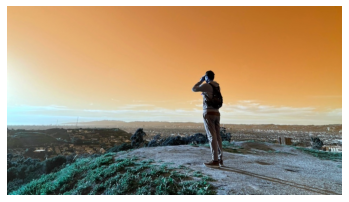

In [3]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("baldwin_hills.jpg", cv2.IMREAD_COLOR)

#img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
# img = img[:,:,::-1]

plt.xticks([]), plt.yticks([]), plt.axis("off")
plt.imshow(img)
plt.show()

반투명한 상자를 덧그리는 예제입니다. 더 다양한 도형 그리는 방법은 [공식 문서](https://docs.opencv.org/4.x/dc/da5/tutorial_py_drawing_functions.html)를 참고하세요.

In [8]:
import cv2
import numpy as np

img = cv2.imread("baldwin_hills.jpg", cv2.IMREAD_COLOR)

# 반투명 상자 그리기
overlay = np.zeros(img.shape, dtype=np.uint8)
alpha = np.zeros(
    (*img.shape[:2], 1), dtype=np.float64
)  # (img.shape[0], img.shape[1], 1)
#print(img.shape[:])

# BGR 사용, thickiness=-1은 채우기. 
# openCV는 outline 옵션이 없어서 속이 꽉찬 박스와 속이 텅빈 박스를 각각 따로 그린다.
overlay = cv2.rectangle(
    overlay, pt1=(520, 180), pt2=(640, 480), color=(255, 0, 0), thickness=-1 #pt1 : 좌측상단, pt2 우측하단
)
overlay = cv2.rectangle(
    overlay, pt1=(520, 180), pt2=(640, 480), color=(255, 0, 0), thickness=1
)
# Color에 원하는 alpha 설정
alpha = cv2.rectangle(alpha, pt1=(520, 180), pt2=(640, 480), color=(0.1), thickness=-1)
alpha = cv2.rectangle(alpha, pt1=(520, 180), pt2=(640, 480), color=(0.5), thickness=1)

# Alpha blending
img = img * (1.0 - alpha) + overlay * alpha
img = img.clip(0, 255).astype(np.uint8)

cv2.imshow("Image", img)
cv2.waitKey(0)
cv2.destroyAllWindows()

(540, 960, 3)


### 동영상 다루기



[동영상 읽어서 재생하기](https://docs.opencv.org/4.x/dd/d43/tutorial_py_video_display.html)

In [11]:
# 기본적인 동영상 재생
import cv2

cap = cv2.VideoCapture("firework.mp4") #여기부터 동영상 여는 코드
# cap = cv2.VideoCapture(0) # 웹캠 사용

if not cap.isOpened():
    print("Error opening video  file")

fps = cap.get(cv2.CAP_PROP_FPS) #동영상이 가진 다양한 성질을 알 수 있음. 여기선 fps를 살펴보자

print("FPS", fps)

while cap.isOpened(): #여기부터 동영상 열려있으면 1프레임씩 그려주는 코드

    ret, frame = cap.read()

    # if frame is read correctly ret is True
    if not ret:
        print("Can't receive frame.")
        break

        # 동영상을 반복하고 싶다면 break 대신에
        # 첫 프레임으로 이동해서 다시 읽어들이기
        # cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
        # ret, frame = cap.read()

    cv2.imshow("Frame", frame)

    # fps로부터 대기 시간 계산
    # 'q' 키를 눌렀다면 종료
    # 주의: 실제 재생 속도의 정확도를 보장하지 않음
    if cv2.waitKey(int(1000.0 / fps)) == ord("q"):
        break

cap.release() #여기부터 동영상 종료 코드
cv2.destroyAllWindows()

FPS 23.99706906026745


동영상 쓰기

In [12]:
# 동영상 저장
import cv2

cap = cv2.VideoCapture("firework.mp4")

if not cap.isOpened():
    print("Error opening video  file")
else:
    # 비디오 파일의 해상도 확인
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)

# 출력 파일 설정
# 비디오 코덱 설정
fourcc = cv2.VideoWriter_fourcc(*"X264")
# 주의: 해상도에 정수 사용
out = cv2.VideoWriter("output.mp4", fourcc, fps, (int(width), int(height))) #원본의 해상도 읽어와서 videowriter 초기화에 사용

while cap.isOpened():

    ret, frame = cap.read()

    # if frame is read correctly ret is True
    if not ret:
        print("Can't receive frame.")
        break

    out.write(frame)
    cv2.imshow("Frame", frame)

    if cv2.waitKey(int(1000.0 / fps)) == ord("q"):
        break

cap.release()
out.release()  # 닫아주기
cv2.destroyAllWindows()

Can't receive frame.


##### [실습] [putText()](https://docs.opencv.org/4.x/d6/d6e/group__imgproc__draw.html#ga5126f47f883d730f633d74f07456c576)로 텍스트 추가하기

In [13]:
# 동영상 저장
import cv2

cap = cv2.VideoCapture("firework.mp4")

In [49]:
#실습
import cv2

cap = cv2.VideoCapture("firework.mp4")

while cap.isOpened(): #여기부터 동영상 열려있으면 1프레임씩 그려주는 코드
    ret, frame = cap.read()

    if not ret:
        print("Can't receive frame.")
        break

    cv2.putText(frame, "I love you Jisoo", (int(10), int(20)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    cv2.imshow("Frame", frame)

    if cv2.waitKey(int(1000.0 / fps)) == ord("q"):
        break

cap.release() #여기부터 동영상 종료 코드
cv2.destroyAllWindows()

Can't receive frame.


In [22]:
#정답
import cv2

cap = cv2.VideoCapture("firework.mp4")

if not cap.isOpened():
    print("Error opening video  file")
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)

fourcc = cv2.VideoWriter_fourcc(*"X264")
out = cv2.VideoWriter("output.mp4", fourcc, fps, (int(width), int(height))) 

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        print("Can't receive frame.")
        break

    # 텍스트 추가
    font = cv2.FONT_HERSHEY_SIMPLEX
    frame = cv2.putText(
        frame, "Fireworks!", (50, 50), font, 1, (255,255,255), 2, cv2.LINE_AA
    ) #line_AA는 anti-aliasing 부드럽게 글짜 그려준다

    out.write(frame)
    cv2.imshow("Frame", frame)

    if cv2.waitKey(int(1000.0 / fps)) == ord("q"):
        break

cap.release()
out.release()  
cv2.destroyAllWindows()

웹캠도 비슷한 방식으로 다룰 수 있습니다.

### GUI


[마우스 클릭 이벤트](https://docs.opencv.org/3.4/db/d5b/tutorial_py_mouse_handling.html)

In [23]:
import numpy as np
from random import randint
import cv2 as cv  # cv로 줄여서 쓰는 경우도 많습니다.

#대부분의 일은 클릭했을 때 발생하는 callback function에서 수행된다
# Mouse callback function
def draw_circle(event, x, y, flags, param):

    # flags 예시: if event == cv2.EVENT_LBUTTONDOWN and flags != cv2.EVENT_FLAG_SHIFTKEY: 
    # flags는 shift키나 ctrl 키를 눌렀는지 판단하는 데 사용
    if event == cv.EVENT_LBUTTONDOWN:
        # 전역 변수 img 사용
        # Numpy is mutable
        cv.circle(
            img,
            (x, y),
            randint(5, 30),
            (randint(0, 255), randint(0, 255), randint(0, 255)),
            -1,
        )

        # param 사용 예시
        param[0] += 1
        print("Num of clicks = ", param[0])

        # global 변수를 사용하는 경우가 더 많습니다.
        # click_number[0] += 1
        # print("Num of clicks = ", click_number[0])


# 하얀 바탕 화면
img = np.full((512, 512, 3), (255, 255, 255), dtype=np.uint8)

cv.namedWindow("Image")  # 창(Window)의 이름 주의. openCV에서는 창에 붙인 이름으로 윈도우 개체를 구별한다.

# param 사용 예시 (가변 자료형 사용)... 클릭할 때마다 [0]을 파라미터로 넘겨준다
click_number = [0]

# 마우스 이벤트 콜백 연결
cv.setMouseCallback("Image", draw_circle, click_number)

while True:

    cv.imshow("Image", img)

    if cv.waitKey(20) == ord("q"):
        break

cv.destroyAllWindows()

Num of clicks =  1
Num of clicks =  2
Num of clicks =  3
Num of clicks =  4
Num of clicks =  5
Num of clicks =  6
Num of clicks =  7
Num of clicks =  8
Num of clicks =  9
Num of clicks =  10
Num of clicks =  11
Num of clicks =  12
Num of clicks =  13
Num of clicks =  14
Num of clicks =  15
Num of clicks =  16
Num of clicks =  17
Num of clicks =  18
Num of clicks =  19
Num of clicks =  20
Num of clicks =  21
Num of clicks =  22
Num of clicks =  23
Num of clicks =  24
Num of clicks =  25
Num of clicks =  26
Num of clicks =  27
Num of clicks =  28
Num of clicks =  29
Num of clicks =  30
Num of clicks =  31


##### [실습] 마우스로 선 그리기

In [ ]:
import numpy as np
from random import randint
import cv2 as cv  # cv로 줄여서 쓰는 경우도 많습니다.

In [48]:
#실습

def draw_circle(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN:

        cv.circle(
            img,
            (x, y),
            5,
            (randint(0, 255), randint(0, 255), randint(0, 255)),
            -1,
        )

        global prev_click
        if prev_click:
            cv.line(
                img, prev_click, (x, y), (255,0,0), 2
            )
        prev_click = (int(x), int(y))



img = np.full((512, 512, 3), (255, 255, 255), dtype=np.uint8)

cv.namedWindow("Practice") 

prev_click = ()

cv.setMouseCallback("Practice", draw_circle)

while True:

    cv.imshow("Practice", img)

    if cv.waitKey(20) == ord("q"):
        break

cv.destroyAllWindows()


In [27]:
#정답
def draw_circle(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN:

        cv.circle(
            img,
            (x, y),
            5,
            (randint(0, 255), randint(0, 255), randint(0, 255)),
            -1,
        )

        global prev_click
        if prev_click:
            cv.line(
                img, 
                prev_click, 
                (x, y), 
                (randint(0, 255), randint(0, 255), randint(0, 255)), 
                1,
            )

        prev_click = [x, y]

img = np.full((512, 512, 3), (255, 255, 255), dtype=np.uint8)
prev_click = None #이전 클릭 저장

cv.namedWindow("Practice") 
cv.setMouseCallback("Practice", draw_circle)

while True:

    cv.imshow("Practice", img)

    if cv.waitKey(20) == ord("q"):
        break

cv.destroyAllWindows()

[트랙바(Trackbar)](https://docs.opencv.org/3.4/d9/dc8/tutorial_py_trackbar.html)

In [35]:
import numpy as np
import cv2 as cv


def update_blue(x):
    color[0] = x
    img[:] = color

def update_green(x):
    color[1] = x
    img[:] = color
    
def update_red(x):
    color[2] = x
    img[:] = color

color = [0, 0, 0] # 시작할 때의 색, 가변형 사용
img = np.full((300, 512, 3), color, np.uint8)

cv.namedWindow("Image")

# create trackbars for color change
cv.createTrackbar("Red", "Image", 0, 255, update_red)
cv.createTrackbar("Green", "Image", 0, 255, update_green)
cv.createTrackbar("Blue", "Image", 0, 255, update_blue)

while True:

    cv2.imshow("Image", img)

    if cv2.waitKey(1) == ord('q'):
        break

    # getTrackbarPro() 사용 예시
    #r = cv.getTrackbarPos("R", "image")

cv2.destroyAllWindows()

##### [실습] 이미지 흐리게 만들기 ([Gaussian Blur](https://docs.opencv.org/3.4/d4/d13/tutorial_py_filtering.html))

[Convolution](https://towardsdatascience.com/intuitively-understanding-convolutions-for-deep-learning-1f6f42faee1)의 직관적인 이해



In [30]:
import cv2
import numpy as np

img = cv2.imread("baldwin_hills.jpg")
# 주의: 1이상 홀수
img = cv2.GaussianBlur(img, (25, 25), 0) 

# 이미지 창 띄우기
cv2.imshow("Image", img)  # img는 BGR
cv2.waitKey(0)  # 0은 무한히 기다린다는 의미
cv2.destroyAllWindows()

In [44]:
#실습
import numpy as np
import cv2

def update_blur(x):
    global blurProperty, img
    blurProperty[0] = x
    blurProperty[1] = x
    img = cv2.GaussianBlur(img, blurProperty, 0) 

img = cv2.imread("baldwin_hills.jpg")

blurProperty = [1, 1]
cv2.namedWindow("Practice")
cv2.createTrackbar("Blur", "Practice", 1, 100, update_blur)

while True:
    cv2.imshow("Practice", img)
    if cv2.waitKey(1) == ord('q'):
        break

cv2.destroyAllWindows()


In [47]:
#정답
import numpy as np
import cv2

def update_strength(x):
    global img
    img = cv2.GaussianBlur(original, (x*2 + 1, x *2 + 1), 0) 

original = cv2.imread("baldwin_hills.jpg")

img = original
cv2.namedWindow("Image")
cv2.createTrackbar("strength", "Image", 0, 40, update_strength)

while True:
    cv2.imshow("Practice", img)
    if cv2.waitKey(1) == ord('q'):
        break

cv2.destroyAllWindows()